# The Atlantic trade in one decade: the 1790s

A map of where people were embarked in Africa and where they were landed in the Americas,
for voyages arriving in 1790–1799. The 1790s were the third-largest decade of the whole
trade, the decade when the most people were landed in Jamaica, and the last full decade
before Britain and the United States abolished their slave trades in 1807–1808.

Flows run from the voyage's imputed principal region of embarkation to its imputed region
of disembarkation, sized by imputed people disembarked. Each region is drawn at its point in
the library's places table (its main port, or its centre).

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import patheffects

import voyages
from voyages import Voyages

v = Voyages()
FIRST, LAST = 1790, 1799
decade = v.transatlantic.between(FIRST, LAST)
rows = decade.to_pandas(
    [
        "voyage_id",
        "year_arrived_imputed",
        "embarkation_region",
        "embarkation_region_name",
        "disembarkation_region",
        "disembarkation_region_name",
        "disembarkation_broad_region_name",
        "embarked_imputed",
        "disembarked_imputed",
    ]
)
summary = pd.Series(
    {
        "voyages": len(rows),
        "embarked": int(rows.embarked_imputed.sum()),
        "disembarked": int(rows.disembarked_imputed.sum()),
    }
)
summary

voyages          2916
embarked       780221
disembarked    701818
dtype: int64

## Flows

People disembarked, by region of embarkation and region of disembarkation, largest first.

In [2]:
flows = (
    rows.groupby(["embarkation_region", "disembarkation_region"])
    .agg(
        embarked_in=("embarkation_region_name", "first"),
        landed_in=("disembarkation_region_name", "first"),
        voyages=("voyage_id", "size"),
        people=("disembarked_imputed", "sum"),
    )
    .reset_index()
    .sort_values("people", ascending=False)
)
flows["people"] = flows.people.astype(int)
flows["share (%)"] = (flows.people / summary.disembarked * 100).round(1)
flows.head(15)[["embarked_in", "landed_in", "voyages", "people", "share (%)"]]

,embarked_in,landed_in,voyages,people,share (%)
145,West Central Africa and St. Helena,Southeast Brazil,227,84099,12.0
107,Bight of Biafra and Gulf of Guinea islands,Jamaica,194,62926,9.0
97,Bight of Benin,Bahia,188,51157,7.3
132,West Central Africa and St. Helena,Jamaica,115,37048,5.3
143,West Central Africa and St. Helena,Bahia,95,35044,5.0
138,West Central Africa and St. Helena,Saint-Domingue,94,31108,4.4
68,Gold Coast,Jamaica,85,23810,3.4
163,Other Africa,Cuba,103,13523,1.9
105,Bight of Biafra and Gulf of Guinea islands,Grenada,55,12619,1.8
18,Senegambia and offshore Atlantic,Amazonia,67,12365,1.8


In [3]:
destinations = (
    rows.groupby("disembarkation_region_name").disembarked_imputed.sum().astype(int)
).sort_values(ascending=False)
destinations.head(12)

disembarkation_region_name
Jamaica               150536
Bahia                  88674
Southeast Brazil       85793
Saint-Domingue         73817
Grenada                34640
Cuba                   28882
British Guiana         23943
St. Vincent            21599
Barbados               18797
Martinique             18634
Amazonia               18528
Danish West Indies     13366
Name: disembarked_imputed, dtype: int64

The three largest flows went to three different empires: West Central Africa to south-east
Brazil (Rio de Janeiro), the Bight of Biafra to Jamaica, and the Bight of Benin to Bahia.
Jamaica was the largest single destination of the decade, with about a fifth of everyone
landed.

## Map

Flows of at least 1,000 people, coloured by the African region of embarkation. Upper Guinea
groups Senegambia, Sierra Leone and the Windward Coast. Flows from Southeast Africa are
drawn round the Cape of Good Hope. Lines are straight on the map: they show where people
were taken, not the ships' tracks. The map leaves out flows with no point to draw: the
region of embarkation is "Other Africa" (not known) or a region is missing.

In [4]:
points = v.sql(
    "SELECT code, name, map_lat AS lat, map_lon AS lon FROM places WHERE level = 'region'"
).to_pandas().set_index("code")  # fmt: skip

GROUP = {
    60100: "Upper Guinea",
    60200: "Upper Guinea",
    60300: "Upper Guinea",
    60400: "Gold Coast",
    60500: "Bight of Benin",
    60600: "Bight of Biafra",
    60700: "West Central Africa",
    60800: "Southeast Africa",
}
ORDER = [
    "Bight of Biafra",
    "Gold Coast",
    "West Central Africa",
    "Bight of Benin",
    "Upper Guinea",
    "Southeast Africa",
]
COLOURS = dict(
    zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"], strict=True)
)
MIN_PEOPLE = 1_000

flows["group"] = flows.embarkation_region.map(GROUP)
drawable = (
    flows.group.notna()
    & flows.embarkation_region.isin(points.dropna().index)
    & flows.disembarkation_region.isin(points.dropna().index)
)
drawn = flows[drawable & (flows.people >= MIN_PEOPLE)].copy()
not_drawn = pd.Series(
    {
        "no region or no point": int(rows.disembarked_imputed.sum() - flows[drawable].people.sum()),
        f"flows under {MIN_PEOPLE:,}": int(
            flows[drawable & (flows.people < MIN_PEOPLE)].people.sum()
        ),
        "drawn": int(drawn.people.sum()),
    }
)
not_drawn.to_frame("people").assign(share=lambda d: (d.people / summary.disembarked * 100).round(1))

,people,share
no region or no point,103274,14.7
"flows under 1,000",35427,5.0
drawn,563117,80.2


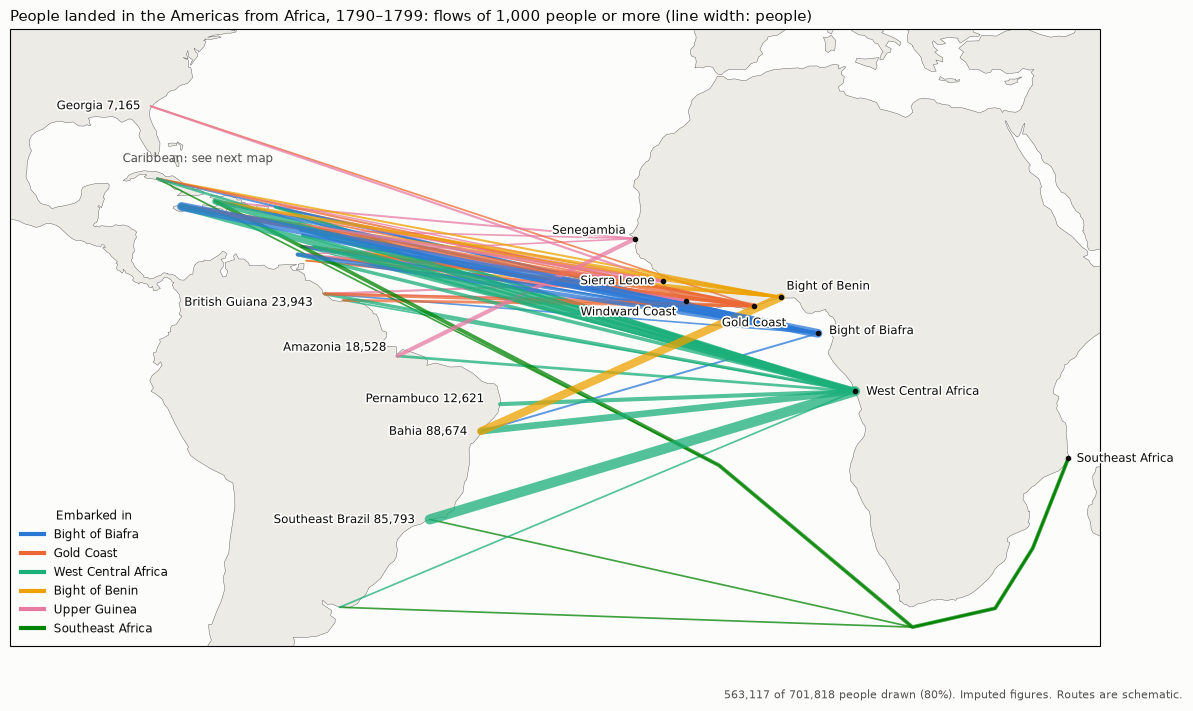

In [5]:
SURFACE, INK, MUTED, LAND = "#fcfcfb", "#0b0b0b", "#52514e", "#ecebe6"
# Flows from Southeast Africa are drawn round the Cape of Good Hope, and on to the
# Caribbean and North America by way of St Helena, roughly as ships sailed.
ROUND_CAPE = [(36.0, -27.0), (31.0, -35.0), (20.0, -37.5)]
ST_HELENA = (-5.7, -16.0)
HALO = [patheffects.withStroke(linewidth=2.5, foreground=SURFACE)]
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})


def width(people: int) -> float:
    return 0.3 + 7 * (people / drawn.people.max()) ** 0.5


def path(start: int, end: int) -> tuple[list[float], list[float]]:
    a, b = points.loc[start], points.loc[end]
    via = []
    if GROUP.get(start) == "Southeast Africa":
        via = ROUND_CAPE + ([] if b.lat < -5 else [ST_HELENA])
    lons, lats = zip(*[(a.lon, a.lat), *via, (b.lon, b.lat)], strict=True)
    return list(lons), list(lats)


def base_map(ax, extent):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor=LAND, edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor=MUTED)
    ax.set_facecolor(SURFACE)


fig = plt.figure(figsize=(12, 7.2))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
base_map(ax, [-100, 45, -40, 42])
for f in drawn.sort_values("people").itertuples():  # largest on top
    xs, ys = path(f.embarkation_region, f.disembarkation_region)
    ax.plot(
        xs, ys, transform=ccrs.PlateCarree(), color=COLOURS[f.group], linewidth=width(f.people),
        alpha=0.75, solid_capstyle="round",
    )  # fmt: skip

# Labels: African regions, and the largest destinations outside the Caribbean.
AFRICA_LABELS = {
    60100: ("Senegambia", (-6, 6, "right")),
    60200: ("Sierra Leone", (-6, 0, "right")),
    60300: ("Windward Coast", (-6, -8, "right")),
    60400: ("Gold Coast", (0, -12, "center")),
    60500: ("Bight of Benin", (4, 8, "left")),
    60600: ("Bight of Biafra", (8, 2, "left")),
    60700: ("West Central Africa", (8, 0, "left")),
    60800: ("Southeast Africa", (6, 0, "left")),
}
for code, (name, (dx, dy, ha)) in AFRICA_LABELS.items():
    p = points.loc[code]
    ax.plot(p.lon, p.lat, "o", color=INK, markersize=3, transform=ccrs.PlateCarree())
    ax.annotate(
        name, (p.lon, p.lat), xytext=(dx, dy), textcoords="offset points", ha=ha,
        va="center", fontsize=8.5, transform=ccrs.PlateCarree(), path_effects=HALO,
    )  # fmt: skip
AMERICAS_LABELS = {
    "Southeast Brazil": (-8, 0, "right"),
    "Bahia": (-8, 0, "right"),
    "Pernambuco": (-8, 4, "right"),
    "Amazonia": (-6, 6, "right"),
    "British Guiana": (-6, -6, "right"),
    "Georgia": (-6, 0, "right"),
}
by_name = points.reset_index().set_index("name")
for name, (dx, dy, ha) in AMERICAS_LABELS.items():
    p = by_name.loc[name]
    ax.annotate(
        f"{name} {destinations[name]:,}", (p.lon, p.lat), xytext=(dx, dy),
        textcoords="offset points", ha=ha, va="center", fontsize=8.5,
        transform=ccrs.PlateCarree(), path_effects=HALO,
    )  # fmt: skip
ax.annotate(
    "Caribbean: see next map", (-75, 21), xytext=(0, 18), textcoords="offset points",
    ha="center", fontsize=8.5, color=MUTED, transform=ccrs.PlateCarree(),
)  # fmt: skip
handles = [plt.Line2D([], [], color=COLOURS[g], linewidth=3) for g in ORDER]
ax.legend(
    handles, ORDER, title="Embarked in", loc="lower left", frameon=False, fontsize=8.5,
    title_fontsize=8.5,
)  # fmt: skip
ax.set_title(
    f"People landed in the Americas from Africa, {FIRST}–{LAST}: flows of {MIN_PEOPLE:,} "
    "people or more (line width: people)",
    loc="left", fontsize=11,
)  # fmt: skip
fig.text(
    0.99, 0.01,
    f"{not_drawn['drawn']:,} of {summary.disembarked:,} people drawn "
    f"({not_drawn['drawn'] / summary.disembarked:.0%}). Imputed figures. Routes are schematic.",
    ha="right", fontsize=8, color=MUTED,
)  # fmt: skip
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/08_flows_1790s.png", dpi=150)

## The Caribbean

The same flows, ending in the Caribbean and the Guianas, with each destination's total.
Saint-Domingue's arrivals fall mostly in 1790–1791: the revolution that began in August
1791 ended the trade there.

In [6]:
saint_domingue = rows[rows.disembarkation_region_name == "Saint-Domingue"]
sd_years = saint_domingue.groupby("year_arrived_imputed").disembarked_imputed.sum().astype(int)
sd_years

year_arrived_imputed
1790    41248
1791    21744
1792     8064
1793     1095
1794      594
1795      575
1796      344
1797      153
Name: disembarked_imputed, dtype: int64

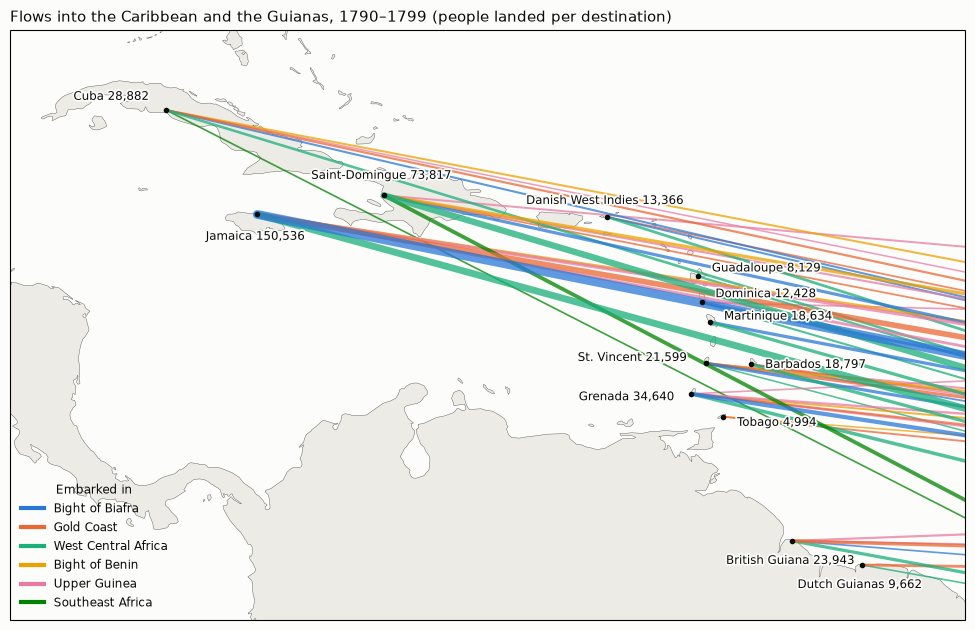

In [7]:
CARIBBEAN_LABELS = {
    "Jamaica": (0, -16, "center"),
    "Saint-Domingue": (0, 14, "center"),
    "Cuba": (-10, 10, "right"),
    "Grenada": (-10, -2, "right"),
    "St. Vincent": (-10, 4, "right"),
    "Barbados": (10, 0, "left"),
    "Martinique": (10, 4, "left"),
    "Dominica": (10, 6, "left"),
    "Guadaloupe": (10, 6, "left"),
    "Danish West Indies": (0, 12, "center"),
    "Tobago": (10, -4, "left"),
    "British Guiana": (0, -14, "center"),
    "Dutch Guianas": (0, -14, "center"),
}
fig = plt.figure(figsize=(12, 6.4))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
EXTENT = [-86, -52, 4, 25]
base_map(ax, EXTENT)
caribbean = drawn[drawn.landed_in.isin(CARIBBEAN_LABELS)]
for f in caribbean.sort_values("people").itertuples():
    xs, ys = path(f.embarkation_region, f.disembarkation_region)
    ax.plot(
        xs, ys, transform=ccrs.PlateCarree(), color=COLOURS[f.group], linewidth=width(f.people),
        alpha=0.75, solid_capstyle="round",
    )  # fmt: skip
for name, (dx, dy, ha) in CARIBBEAN_LABELS.items():
    p = by_name.loc[name]
    ax.plot(p.lon, p.lat, "o", color=INK, markersize=3, transform=ccrs.PlateCarree())
    ax.annotate(
        f"{name} {destinations[name]:,}", (p.lon, p.lat), xytext=(dx, dy),
        textcoords="offset points", ha=ha, va="center", fontsize=8.5,
        transform=ccrs.PlateCarree(), path_effects=HALO,
    )  # fmt: skip
ax.legend(
    handles, ORDER, title="Embarked in", loc="lower left", frameon=False, fontsize=8.5,
    title_fontsize=8.5,
)  # fmt: skip
ax.set_title(
    f"Flows into the Caribbean and the Guianas, {FIRST}–{LAST} (people landed per destination)",
    loc="left", fontsize=11,
)  # fmt: skip
fig.tight_layout()
fig.savefig("figures/08_caribbean_1790s.png", dpi=150)

## Jamaica in the 1790s

Where the people landed in Jamaica in this decade had embarked.

In [8]:
to_jamaica = rows[rows.disembarkation_region_name == "Jamaica"]
jamaica = (
    to_jamaica.groupby("embarkation_region_name")
    .disembarked_imputed.sum()
    .astype(int)
    .sort_values(ascending=False)
    .to_frame("people")
    .assign(share=lambda d: (d.people / d.people.sum() * 100).round(1))
)
jamaica

,people,share
embarkation_region_name,,
Bight of Biafra and Gulf of Guinea islands,62926,41.9
West Central Africa and St. Helena,37048,24.7
Gold Coast,23810,15.9
Sierra Leone,7759,5.2
Other Africa,6481,4.3
Bight of Benin,6081,4.0
Windward Coast,5181,3.4
Senegambia and offshore Atlantic,934,0.6


- More than two in five of the people landed in Jamaica in the 1790s came from the Bight of
  Biafra, a quarter from West Central Africa and about a sixth from the Gold Coast.
- Jamaica took more people in this decade than any other region of the Americas, ahead of
  Bahia and south-east Brazil.

## Checks

The figures quoted above, checked against the tables.

In [9]:
by_decade = v.transatlantic.by_decade(["voyages", "embarked", "disembarked"]).set_index("decade")
assert summary.tolist() == by_decade.loc[1790, ["voyages", "embarked", "disembarked"]].tolist()
assert by_decade.embarked.rank(ascending=False)[1790] == 3
top3 = flows.head(3)[["embarked_in", "landed_in"]].values.tolist()
assert top3 == [
    ["West Central Africa and St. Helena", "Southeast Brazil"],
    ["Bight of Biafra and Gulf of Guinea islands", "Jamaica"],
    ["Bight of Benin", "Bahia"],
]
assert destinations.index[0] == "Jamaica" and destinations.Jamaica == 150_536
assert 0.2 < destinations.Jamaica / summary.disembarked < 0.23
assert set(drawn.landed_in) >= set(CARIBBEAN_LABELS) - {"Tobago"}
assert set(AMERICAS_LABELS) | set(CARIBBEAN_LABELS) <= set(by_name.index)
assert sd_years.loc[1790:1791].sum() / sd_years.sum() > 0.8
shares = jamaica.share
assert shares.index[:3].tolist() == [
    "Bight of Biafra and Gulf of Guinea islands",
    "West Central Africa and St. Helena",
    "Gold Coast",
]
assert 40 < shares.iloc[0] < 45 and 23 < shares.iloc[1] < 27 and 15 < shares.iloc[2] < 17

In [10]:
voyages.citation()

'SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 20, 2026).'